# pandas cheatsheet for prediction work

Runnable reference: every cell works on a small made-up dataset, so you can tweak and re-run. Geared to what you do in a prediction project: load, inspect, clean, engineer features (without leakage), aggregate, merge, reshape.

Written for **pandas 2.2+ / 3.x**. Two pandas 3 changes to know:
- **Copy-on-write** is always on: `df2 = df[...]` is effectively a copy, so modifying it never changes `df`, and chained assignment `df[col][mask] = x` *does nothing*. Use `df.loc[mask, col] = x`.
- Text columns default to a dedicated **`str` dtype** (not `object`). Check for text columns with `pd.api.types.is_string_dtype` or "not numeric", not `dtype == object`.

| # | Section |
|---|---|
| 1 | Create, read, write |
| 2 | Inspect |
| 3 | Select and filter |
| 4 | New columns |
| 5 | Missing values |
| 6 | Strings |
| 7 | Dates and time series |
| 8 | Group-by |
| 9 | Merge, join, concat |
| 10 | Reshape |
| 11 | Sort, rank, duplicates |
| 12 | Dtypes and memory |
| 13 | Feature-engineering patterns for ML |
| 14 | Quick plots |
| 15 | Performance and gotchas |

In [1]:
import numpy as np
import pandas as pd
print(pd.__version__)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

3.1.1


## 1. Create, read, write

In [2]:
# A small sales dataset used throughout
n = 12
df = pd.DataFrame({
    "order_id": range(1001, 1001 + n),
    "date": pd.date_range("2024-01-01", periods=n, freq="5D"),
    "customer": ["ann", "bob", "cat", "ann", "dan", "bob", "ann", "cat", "eve", "bob", "dan", "ann"],
    "city": ["London", "Paris", "London", None, "Berlin", "Paris", "London", "London", "Paris", "Paris", "Berlin", "London"],
    "product": ["A-1", "B-2", "A-1", "C-3", "B-2", "A-1", "C-3", "B-2", "A-1", "C-3", "A-1", "B-2"],
    "qty": [1, 3, 2, 1, np.nan, 4, 2, 1, 5, 2, 3, 1],
    "price": [9.5, 20.0, 9.5, 35.0, 20.0, 9.5, 35.0, 20.0, 9.5, 35.0, 9.5, -1.0],
})
df

,order_id,date,customer,city,product,qty,price
0,1001,2024-01-01,ann,London,A-1,1.0,9.5
1,1002,2024-01-06,bob,Paris,B-2,3.0,20.0
2,1003,2024-01-11,cat,London,A-1,2.0,9.5
3,1004,2024-01-16,ann,NaN,C-3,1.0,35.0
4,1005,2024-01-21,dan,Berlin,B-2,NaN,20.0
5,1006,2024-01-26,bob,Paris,A-1,4.0,9.5
6,1007,2024-01-31,ann,London,C-3,2.0,35.0
7,1008,2024-02-05,cat,London,B-2,1.0,20.0
8,1009,2024-02-10,eve,Paris,A-1,5.0,9.5
9,1010,2024-02-15,bob,Paris,C-3,2.0,35.0


```python
# Reading
pd.read_csv("file.csv",
            usecols=["a", "b"],               # only some columns (faster, less memory)
            dtype={"zip": "string"},          # keep leading zeros in codes
            parse_dates=["date"],             # parse while reading
            na_values=["", "NA", -999],       # extra missing-value markers
            nrows=1000)                       # peek at big files
pd.read_parquet("file.parquet")               # fast, keeps dtypes (needs pyarrow)
pd.read_excel("file.xlsx", sheet_name="Sheet1")   # needs openpyxl
pd.read_json("file.json", lines=True)

# Writing
df.to_csv("out.csv", index=False)
df.to_parquet("out.parquet", index=False)     # preferred for intermediate data
```

## 2. Inspect

In [3]:
df.shape, df.columns.tolist()

((12, 7), ['order_id', 'date', 'customer', 'city', 'product', 'qty', 'price'])

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   order_id  12 non-null     int64         
 1   date      12 non-null     datetime64[us]
 2   customer  12 non-null     str           
 3   city      11 non-null     str           
 4   product   12 non-null     str           
 5   qty       11 non-null     float64       
 6   price     12 non-null     float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(3)
memory usage: 940.0 bytes


In [5]:
df.describe()                     # numeric summary; add include="all" for every column

,order_id,date,qty,price
count,12.000,12,11.000,12.000
mean,1006.500,2024-01-28 12:00:00,2.273,17.625
min,1001.000,2024-01-01 00:00:00,1.000,-1.000
25%,1003.750,2024-01-14 18:00:00,1.000,9.500
50%,1006.500,2024-01-28 12:00:00,2.000,14.750
75%,1009.250,2024-02-11 06:00:00,3.000,23.750
max,1012.000,2024-02-25 00:00:00,5.000,35.000
std,3.606,NaN,1.348,12.059


In [6]:
df["city"].value_counts(dropna=False)          # counts incl. NaN; normalize=True for shares

city
London    5
Paris     4
Berlin    2
NaN       1
Name: count, dtype: int64

In [7]:
df.nunique()                                   # distinct values per column

order_id    12
date        12
customer     5
city         3
product      3
qty          5
price        4
dtype: int64

In [8]:
df.isna().sum()                                # missing per column

order_id    0
date        0
customer    0
city        1
product     0
qty         1
price       0
dtype: int64

In [9]:
df.sample(3, random_state=0)                   # random rows (better than head for spotting issues)

,order_id,date,customer,city,product,qty,price
6,1007,2024-01-31,ann,London,C-3,2.0,35.0
11,1012,2024-02-25,ann,London,B-2,1.0,-1.0
4,1005,2024-01-21,dan,Berlin,B-2,NaN,20.0


## 3. Select and filter

In [10]:
df["qty"]                     # one column -> Series
df[["customer", "qty"]]       # several columns -> DataFrame
df.loc[2:4, ["customer", "qty"]]     # by LABEL (inclusive end)
df.iloc[2:4, 0:3]                    # by POSITION (exclusive end)
df.loc[df["qty"] > 2, "customer"]    # boolean mask + column

1     bob
5     bob
8     eve
10    dan
Name: customer, dtype: str

In [11]:
# Combine conditions with & | ~ and parentheses
df[(df["city"] == "London") & (df["qty"] >= 2)]

,order_id,date,customer,city,product,qty,price
2,1003,2024-01-11,cat,London,A-1,2.0,9.5
6,1007,2024-01-31,ann,London,C-3,2.0,35.0


In [12]:
df[df["customer"].isin(["ann", "eve"]) & df["price"].between(5, 25)]

,order_id,date,customer,city,product,qty,price
0,1001,2024-01-01,ann,London,A-1,1.0,9.5
8,1009,2024-02-10,eve,Paris,A-1,5.0,9.5


In [13]:
max_price = 25
df.query("city == 'Paris' and price < @max_price")    # readable; @ refers to Python variables

,order_id,date,customer,city,product,qty,price
1,1002,2024-01-06,bob,Paris,B-2,3.0,20.0
5,1006,2024-01-26,bob,Paris,A-1,4.0,9.5
8,1009,2024-02-10,eve,Paris,A-1,5.0,9.5


In [14]:
df.filter(like="pr")        # columns whose name contains "pr"; regex= also works
df.select_dtypes("number").columns.tolist()

['order_id', 'qty', 'price']

## 4. New columns

In [15]:
df = df.assign(
    revenue=lambda d: d["qty"] * d["price"],                                   # vectorised arithmetic
    big_order=lambda d: np.where(d["qty"] >= 3, "big", "small"),               # if/else
    size=lambda d: np.select([d["qty"] >= 4, d["qty"] >= 2], ["L", "M"], default="S"),   # multi-way if
    qty_bucket=lambda d: pd.cut(d["qty"], bins=[0, 1, 3, np.inf], labels=["1", "2-3", "4+"]),
    price_quartile=lambda d: pd.qcut(d["price"].rank(method="first"), 4, labels=False),   # equal-count bins
    region=lambda d: d["city"].map({"London": "UK", "Paris": "EU", "Berlin": "EU"}),     # lookup
    log_price=lambda d: np.log1p(d["price"].clip(lower=0)),
)
df.head()

,order_id,date,customer,city,product,qty,price,revenue,big_order,size,qty_bucket,price_quartile,region,log_price
0,1001,2024-01-01,ann,London,A-1,1.0,9.5,9.5,small,S,1,0,UK,2.351
1,1002,2024-01-06,bob,Paris,B-2,3.0,20.0,60.0,big,M,2-3,2,EU,3.045
2,1003,2024-01-11,cat,London,A-1,2.0,9.5,19.0,small,M,2-3,0,UK,2.351
3,1004,2024-01-16,ann,NaN,C-3,1.0,35.0,35.0,small,S,1,3,NaN,3.584
4,1005,2024-01-21,dan,Berlin,B-2,NaN,20.0,NaN,small,S,NaN,2,EU,3.045


In [16]:
# Rename / drop / reorder
df.rename(columns={"qty": "quantity"}).drop(columns=["log_price"]).head(2)

,order_id,date,customer,city,product,quantity,price,revenue,big_order,size,qty_bucket,price_quartile,region
0,1001,2024-01-01,ann,London,A-1,1.0,9.5,9.5,small,S,1,0,UK
1,1002,2024-01-06,bob,Paris,B-2,3.0,20.0,60.0,big,M,2-3,2,EU


Avoid `df.apply(f, axis=1)` for row-wise logic when a vectorised version exists: it's a Python loop, typically 10–100× slower.

## 5. Missing values

In [17]:
print(df[["city", "qty", "price"]].isna().sum())
# -1 is a sentinel for "unknown" price: make it NaN first
df.loc[df["price"] < 0, "price"] = np.nan

city     1
qty      1
price    0
dtype: int64


In [18]:
filled = df.assign(
    city=lambda d: d["city"].fillna("Unknown"),
    qty_missing=lambda d: d["qty"].isna().astype(int),          # keep the fact that it was missing
    qty=lambda d: d["qty"].fillna(d["qty"].median()),
    price=lambda d: d["price"].fillna(d.groupby("product")["price"].transform("median")),   # fill within group
)
filled[["city", "qty", "qty_missing", "product", "price"]]

,city,qty,qty_missing,product,price
0,London,1.0,0,A-1,9.5
1,Paris,3.0,0,B-2,20.0
2,London,2.0,0,A-1,9.5
3,Unknown,1.0,0,C-3,35.0
4,Berlin,2.0,1,B-2,20.0
5,Paris,4.0,0,A-1,9.5
6,London,2.0,0,C-3,35.0
7,London,1.0,0,B-2,20.0
8,Paris,5.0,0,A-1,9.5
9,Paris,2.0,0,C-3,35.0


```python
df.dropna(subset=["qty"])     # drop rows missing qty
df.ffill()                    # forward-fill: fine for time series (past -> future)
df.bfill()                    # back-fill: LEAKS the future into the past in time series!
```
For modelling, prefer imputing inside an sklearn `Pipeline` (`SimpleImputer`) so it's fitted on training folds only.

## 6. Strings (`.str`)

In [19]:
s = df["product"]
pd.DataFrame({
    "lower": s.str.lower(),
    "letter": s.str.split("-").str[0],
    "number": s.str.extract(r"(\d+)", expand=False).astype(int),
    "has_A": s.str.contains("A"),
    "len": s.str.len(),
    "padded": s.str.replace("-", "_").str.pad(6, fillchar="0"),
}).head()

,lower,letter,number,has_A,len,padded
0,a-1,A,1,True,3,000A_1
1,b-2,B,2,False,3,000B_2
2,a-1,A,1,True,3,000A_1
3,c-3,C,3,False,3,000C_3
4,b-2,B,2,False,3,000B_2


In [20]:
df["product"].str.split("-", expand=True).rename(columns={0: "family", 1: "variant"}).head(3)

,family,variant
0,A,1
1,B,2
2,A,1


## 7. Dates and time series

In [21]:
d = df["date"]
pd.DataFrame({
    "year": d.dt.year, "month": d.dt.month, "day_of_week": d.dt.day_of_week,   # Monday = 0
    "is_weekend": d.dt.day_of_week >= 5, "week": d.dt.isocalendar().week,
    "month_start": d.dt.to_period("M").dt.to_timestamp(),
    "days_since_start": (d - d.min()).dt.days,
}).head()

,year,month,day_of_week,is_weekend,week,month_start,days_since_start
0,2024,1,0,False,1,2024-01-01,0
1,2024,1,5,True,1,2024-01-01,5
2,2024,1,3,False,2,2024-01-01,10
3,2024,1,1,False,3,2024-01-01,15
4,2024,1,6,True,3,2024-01-01,20


In [22]:
pd.to_datetime(["2024-03-01", "01/04/2024", "not a date"], errors="coerce", format="mixed", dayfirst=True)

DatetimeIndex(['2024-01-03', '2024-04-01', 'NaT'], dtype='datetime64[us]', freq=None)

In [23]:
# Daily series to play with
ts = pd.Series(rng.normal(0, 1, 60).cumsum() + 100, index=pd.date_range("2024-01-01", periods=60, freq="D"), name="price")
out = pd.DataFrame({
    "price": ts,
    "ret": ts.pct_change(),                       # % change from previous row
    "diff": ts.diff(),
    "lag_1": ts.shift(1),                         # yesterday's value (past = safe feature)
    "lead_1": ts.shift(-1),                       # tomorrow's value (future = TARGET only, never a feature)
    "ma_7": ts.rolling(7).mean(),                 # trailing window, uses only past + today
    "ewm_7": ts.ewm(halflife=7, adjust=False).mean(),
    "std_7": ts.rolling(7, min_periods=3).std(),
})
out.head(9)

,price,ret,diff,lag_1,lead_1,ma_7,ewm_7,std_7
2024-01-01,100.126,NaN,NaN,NaN,99.994,NaN,100.126,NaN
2024-01-02,99.994,-0.001,-0.132,100.126,100.634,NaN,100.113,NaN
2024-01-03,100.634,0.006,0.640,99.994,100.739,NaN,100.162,0.338
2024-01-04,100.739,0.001,0.105,100.634,100.203,NaN,100.217,0.368
2024-01-05,100.203,-0.005,-0.536,100.739,100.565,NaN,100.215,0.328
2024-01-06,100.565,0.004,0.362,100.203,101.869,NaN,100.248,0.307
2024-01-07,101.869,0.013,1.304,100.565,102.816,100.590,100.401,0.630
2024-01-08,102.816,0.009,0.947,101.869,102.112,100.974,100.629,1.007
2024-01-09,102.112,-0.007,-0.704,102.816,100.847,101.277,100.769,0.981


In [24]:
ts.resample("W").agg(["first", "last", "mean", "count"]).head()     # daily -> weekly

,first,last,mean,count
2024-01-07,100.126,101.869,100.590,7
2024-01-14,102.816,97.721,100.275,7
2024-01-21,96.475,96.208,95.734,7
2024-01-28,97.574,96.593,97.468,7
2024-02-04,96.135,95.733,95.600,7


Never use `rolling(..., center=True)` for features. It averages the future too.

## 8. Group-by

In [25]:
df = filled.assign(revenue=lambda d: d["qty"] * d["price"])

# Named aggregation: one row per group
df.groupby("customer").agg(
    n_orders=("order_id", "count"),
    total_qty=("qty", "sum"),
    avg_price=("price", "mean"),
    first_order=("date", "min"),
    cities=("city", "nunique"),
).sort_values("total_qty", ascending=False)

,n_orders,total_qty,avg_price,first_order,cities
customer,,,,,
bob,3,9.0,21.500,2024-01-06,1
ann,4,5.0,24.875,2024-01-01,2
dan,2,5.0,14.750,2024-01-21,1
eve,1,5.0,9.500,2024-02-10,1
cat,2,3.0,14.750,2024-01-11,1


In [26]:
# transform: same length as df, so it can be a new column (group statistics as features)
df.assign(
    cust_total_qty=df.groupby("customer")["qty"].transform("sum"),
    share_of_cust_qty=lambda d: d["qty"] / d["cust_total_qty"],
    order_number=df.groupby("customer").cumcount() + 1,                       # 1st, 2nd, … order per customer
    rank_in_city=df.groupby("city")["revenue"].rank(ascending=False),
)[["customer", "qty", "cust_total_qty", "share_of_cust_qty", "order_number", "city", "revenue", "rank_in_city"]]

,customer,qty,cust_total_qty,share_of_cust_qty,order_number,city,revenue,rank_in_city
0,ann,1.0,5.0,0.200,1,London,9.5,5.0
1,bob,3.0,9.0,0.333,1,Paris,60.0,2.0
2,cat,2.0,3.0,0.667,1,London,19.0,4.0
3,ann,1.0,5.0,0.200,2,Unknown,35.0,1.0
4,dan,2.0,5.0,0.400,1,Berlin,40.0,1.0
5,bob,4.0,9.0,0.444,2,Paris,38.0,4.0
6,ann,2.0,5.0,0.400,3,London,70.0,1.0
7,cat,1.0,3.0,0.333,2,London,20.0,2.5
8,eve,5.0,5.0,1.000,1,Paris,47.5,3.0
9,bob,2.0,9.0,0.222,3,Paris,70.0,1.0


In [27]:
df.groupby(["city", "product"], dropna=False)["revenue"].sum().unstack(fill_value=0)   # 2-key group -> table

product,A-1,B-2,C-3
city,,,
Berlin,28.5,40.0,0.0
London,28.5,40.0,70.0
Paris,85.5,60.0,70.0
Unknown,0.0,0.0,35.0


In [28]:
# filter: keep whole groups that satisfy a condition
df.groupby("customer").filter(lambda g: len(g) >= 3)[["customer", "order_id"]]

,customer,order_id
0,ann,1001
1,bob,1002
3,ann,1004
5,bob,1006
6,ann,1007
9,bob,1010
11,ann,1012


## 9. Merge, join, concat

In [29]:
customers = pd.DataFrame({"customer": ["ann", "bob", "cat", "dan", "zed"],
                          "segment": ["gold", "silver", "gold", "bronze", "silver"]})
merged = df.merge(customers, on="customer", how="left", validate="many_to_one", indicator=True)
merged["_merge"].value_counts()

_merge
both          11
left_only      1
right_only     0
Name: count, dtype: int64

- `how`: `left` (keep all of df), `inner`, `outer`, `right`, `cross`.
- **`validate="many_to_one"`** raises if the right table has duplicate keys, which would silently duplicate rows. Use it always.
- `indicator=True` adds `_merge` showing which side each row came from: great for checking unmatched keys.
- Different key names: `left_on="cust_id", right_on="customer"`.

In [30]:
# Stack tables vertically (same columns) or side by side
train_part, test_part = df.iloc[:8], df.iloc[8:]
both = pd.concat([train_part.assign(split="train"), test_part.assign(split="test")], ignore_index=True)
both["split"].value_counts()

split
train    8
test     4
Name: count, dtype: int64

In [31]:
# As-of merge: attach the most recent PAST value (e.g. latest price before each order). Both sides sorted by key.
prices = pd.DataFrame({"date": pd.date_range("2023-12-25", periods=12, freq="6D"), "fx_rate": np.linspace(1.10, 1.20, 12)})
pd.merge_asof(df.sort_values("date"), prices, on="date", direction="backward")[["date", "customer", "fx_rate"]].head()

,date,customer,fx_rate
0,2024-01-01,ann,1.109
1,2024-01-06,bob,1.118
2,2024-01-11,cat,1.118
3,2024-01-16,ann,1.127
4,2024-01-21,dan,1.136


## 10. Reshape

In [32]:
pivot = df.pivot_table(index="customer", columns="product", values="qty", aggfunc="sum", fill_value=0, margins=True)
pivot

product,A-1,B-2,C-3,All
customer,,,,
ann,1.0,1.0,3.0,5.0
bob,4.0,3.0,2.0,9.0
cat,2.0,1.0,0.0,3.0
dan,3.0,2.0,0.0,5.0
eve,5.0,0.0,0.0,5.0
All,15.0,7.0,5.0,27.0


In [33]:
long = pivot.drop(index="All", columns="All").reset_index().melt(id_vars="customer", var_name="product", value_name="qty")
long.head()        # wide -> long

,customer,product,qty
0,ann,A-1,1.0
1,bob,A-1,4.0
2,cat,A-1,2.0
3,dan,A-1,3.0
4,eve,A-1,5.0


In [34]:
pd.crosstab(df["city"], df["big_order"], normalize="index")    # row shares

big_order,big,small
city,,
Berlin,0.50,0.50
London,0.00,1.00
Paris,0.75,0.25
Unknown,0.00,1.00


In [35]:
# explode: one row per list element
pd.DataFrame({"user": ["a", "b"], "tags": [["x", "y"], ["z"]]}).explode("tags")

,user,tags
0,a,x
0,a,y
1,b,z


## 11. Sort, rank, duplicates

In [36]:
df.sort_values(["customer", "date"], ascending=[True, False]).head(4)[["customer", "date", "qty"]]

,customer,date,qty
11,ann,2024-02-25,1.0
6,ann,2024-01-31,2.0
3,ann,2024-01-16,1.0
0,ann,2024-01-01,1.0


In [37]:
df.nlargest(3, "revenue")[["order_id", "customer", "revenue"]]

,order_id,customer,revenue
6,1007,ann,70.0
9,1010,bob,70.0
1,1002,bob,60.0


In [38]:
dup = pd.concat([df, df.iloc[[0, 1]]])
print("duplicated rows:", dup.duplicated().sum())
print("duplicated order_ids:", dup["order_id"].duplicated().sum())
dup.drop_duplicates(subset=["order_id"], keep="last").shape

duplicated rows: 2
duplicated order_ids: 2


(12, 15)

In [39]:
# Latest row per customer
df.sort_values("date").groupby("customer").tail(1)[["customer", "date", "qty"]]

,customer,date,qty
7,cat,2024-02-05,1.0
8,eve,2024-02-10,5.0
9,bob,2024-02-15,2.0
10,dan,2024-02-20,3.0
11,ann,2024-02-25,1.0


## 12. Dtypes and memory

In [40]:
big = pd.DataFrame({"city": rng.choice(["London", "Paris", "Berlin"], 100_000),
                    "x": rng.normal(size=100_000), "n": rng.integers(0, 100, 100_000)})
before = big.memory_usage(deep=True).sum() / 1e6
small = big.astype({"city": "category", "x": "float32"}).assign(n=lambda d: pd.to_numeric(d["n"], downcast="integer"))
after = small.memory_usage(deep=True).sum() / 1e6
print(f"{before:.1f} MB -> {after:.1f} MB"); small.dtypes

3.0 MB -> 0.6 MB


city    category
x        float32
n           int8
dtype: object

In [41]:
pd.to_numeric(pd.Series(["1", "2.5", "n/a"]), errors="coerce")     # bad values -> NaN

0    1.0
1    2.5
2    NaN
dtype: float64

`category` dtype also lets LightGBM/XGBoost use a column as categorical directly.

## 13. Feature-engineering patterns for ML

In [42]:
# (a) Lag / history features PER ENTITY, using only the past: sort, group, shift
df = df.sort_values(["customer", "date"])
g = df.groupby("customer")
feat = df.assign(
    prev_qty=g["qty"].shift(1),                                               # previous order's qty
    days_since_prev=g["date"].diff().dt.days,
    past_mean_qty=g["qty"].transform(lambda s: s.shift(1).expanding().mean()),   # mean of PREVIOUS orders only
    past_orders=g.cumcount(),
)
feat[["customer", "date", "qty", "prev_qty", "days_since_prev", "past_mean_qty", "past_orders"]]

,customer,date,qty,prev_qty,days_since_prev,past_mean_qty,past_orders
0,ann,2024-01-01,1.0,NaN,NaN,NaN,0
3,ann,2024-01-16,1.0,1.0,15.0,1.000,1
6,ann,2024-01-31,2.0,1.0,15.0,1.000,2
11,ann,2024-02-25,1.0,2.0,25.0,1.333,3
1,bob,2024-01-06,3.0,NaN,NaN,NaN,0
5,bob,2024-01-26,4.0,3.0,20.0,3.000,1
9,bob,2024-02-15,2.0,4.0,20.0,3.500,2
2,cat,2024-01-11,2.0,NaN,NaN,NaN,0
7,cat,2024-02-05,1.0,2.0,25.0,2.000,1
4,dan,2024-01-21,2.0,NaN,NaN,NaN,0


The `shift(1)` before `expanding()` matters: without it, the row's own value (often the target) leaks into its feature.

In [43]:
# (b) One-hot encoding
pd.get_dummies(df[["city", "product"]], dummy_na=True, dtype=int).head(3)

,city_Berlin,city_London,city_Paris,city_Unknown,city_nan,product_A-1,product_B-2,product_C-3,product_nan
0,0,1,0,0,0,1,0,0,0
3,0,0,0,1,0,0,0,1,0
6,0,1,0,0,0,0,0,1,0


In [44]:
# (c) Frequency encoding: how common is this category?
df["product_freq"] = df["product"].map(df["product"].value_counts(normalize=True))
df[["product", "product_freq"]].drop_duplicates()

,product,product_freq
0,A-1,0.417
3,C-3,0.250
11,B-2,0.333


In [45]:
# (d) Out-of-fold target encoding (each row's encoding comes from OTHER folds: no leakage)
from sklearn.model_selection import KFold

def oof_target_encode(data, col, target, n_splits=4, smoothing=5, seed=0):
    enc = pd.Series(np.nan, index=data.index)
    prior = data[target].mean()
    for tr, va in KFold(n_splits, shuffle=True, random_state=seed).split(data):
        stats = data.iloc[tr].groupby(col)[target].agg(["mean", "count"])
        smooth = (stats["mean"] * stats["count"] + prior * smoothing) / (stats["count"] + smoothing)
        enc.iloc[va] = data.iloc[va][col].map(smooth).fillna(prior).values
    return enc

df["product_te"] = oof_target_encode(df, "product", "revenue")
df[["product", "revenue", "product_te"]].head()

,product,revenue,product_te
0,A-1,9.5,35.703
3,C-3,35.0,47.232
6,C-3,70.0,42.232
11,B-2,20.0,38.828
1,B-2,60.0,33.828


In [46]:
# (e) Ratios and interactions
df.assign(rev_per_unit=lambda d: d["revenue"] / d["qty"].replace(0, np.nan),
          city_product=lambda d: d["city"].fillna("NA") + "_" + d["product"])[["rev_per_unit", "city_product"]].head(3)

,rev_per_unit,city_product
0,9.5,London_A-1
3,35.0,Unknown_C-3
6,35.0,London_C-3


In [47]:
# (f) Method chaining with .pipe: a readable cleaning pipeline
def drop_bad_prices(d):  return d[d["price"] > 0]
def add_revenue(d):      return d.assign(revenue=d["qty"] * d["price"])

clean = (df.pipe(drop_bad_prices)
           .pipe(add_revenue)
           .loc[:, ["order_id", "customer", "revenue"]]
           .reset_index(drop=True))
clean.head(3)

,order_id,customer,revenue
0,1001,ann,9.5
1,1004,ann,35.0
2,1007,ann,70.0


## 14. Quick plots
pandas wraps matplotlib, so exploration plots are one-liners. For presentation-quality versions see `code_templates.ipynb`.

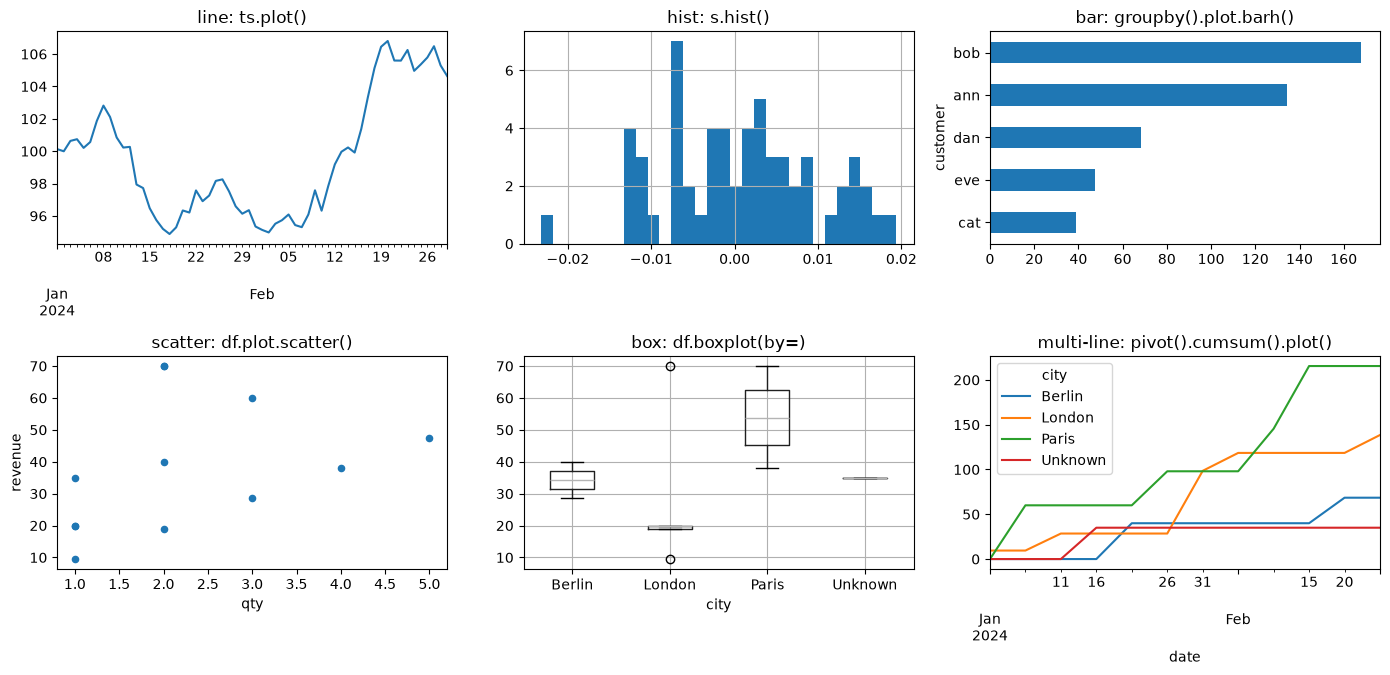

In [48]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
ts.plot(ax=axes[0, 0], title="line: ts.plot()")
ts.pct_change().hist(bins=30, ax=axes[0, 1]); axes[0, 1].set_title("hist: s.hist()")
df.groupby("customer")["revenue"].sum().sort_values().plot.barh(ax=axes[0, 2], title="bar: groupby().plot.barh()")
df.plot.scatter(x="qty", y="revenue", ax=axes[1, 0], title="scatter: df.plot.scatter()")
df.boxplot(column="revenue", by="city", ax=axes[1, 1]); axes[1, 1].set_title("box: df.boxplot(by=)")
df.pivot_table(index="date", columns="city", values="revenue", aggfunc="sum").fillna(0).cumsum().plot(ax=axes[1, 2], title="multi-line: pivot().cumsum().plot()")
plt.suptitle(""); plt.tight_layout()
plt.show()

## 15. Performance and gotchas

**Speed**
- Vectorise: column arithmetic, `np.where`, `np.select`, `.str`, `.dt`, `groupby().transform` beat `apply` and loops.
- Never grow a DataFrame row by row in a loop: collect a list of dicts and build once with `pd.DataFrame(rows)`.
- `itertuples()` is much faster than `iterrows()` if you truly must loop.
- Read only needed columns (`usecols`), use `category` / `float32`, save intermediates as Parquet.

In [49]:
import time
big = pd.DataFrame({"a": rng.normal(size=200_000), "b": rng.normal(size=200_000)})
t = time.time(); r1 = big.apply(lambda r: r["a"] * 2 if r["b"] > 0 else 0.0, axis=1); t_apply = time.time() - t
t = time.time(); r2 = np.where(big["b"] > 0, big["a"] * 2, 0.0); t_vec = time.time() - t
print(f"apply: {t_apply:.2f}s | np.where: {t_vec:.4f}s | same result: {np.allclose(r1, r2)}")

apply: 2.30s | np.where: 0.0023s | same result: True


**Gotchas**

| Gotcha | Example | Do instead |
|---|---|---|
| Chained assignment does nothing (pandas 3) | `df[df.a > 0]["b"] = 1` | `df.loc[df.a > 0, "b"] = 1` |
| `and`/`or` on Series raise errors | `df[(df.a > 0) and (df.b < 1)]` | `&`, `\|`, `~` with parentheses |
| NaN never equals NaN | `df[df.x == np.nan]` is empty | `df[df.x.isna()]` |
| Integer column becomes float when NaN appears | `[1, 2, NaN]` → float64 | nullable `"Int64"` dtype if it matters |
| Merge silently duplicates rows | duplicate keys on the right | `validate="many_to_one"`, check row counts |
| Index alignment surprises | `s1 + s2` aligns on index, not position | `.reset_index(drop=True)` or `.to_numpy()` |
| `groupby` drops NaN keys | missing cities vanish | `groupby(..., dropna=False)` |
| Future data in features | `bfill`, `center=True`, full-sample `transform("mean")` on time data | `shift`, trailing windows, expanding stats |
| `inplace=True` | rarely saves memory, breaks chaining | reassign: `df = df.dropna()` |